In [1]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
import torch.optim as optim
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import os
from pathlib import Path
ROOT = Path.cwd().resolve()
DATA_DIR = ROOT / 'data'
CHECKPOINT_DIR = ROOT / 'checkpoints'
OUTPUT_DIR = ROOT / 'outputs'
CHECKPOINT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)


I0000 00:00:1790722310.513832 2399561 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import pandas as pd
import numpy as np
import torch
import sklearn
import matplotlib
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("torch:", torch.__version__)
print("sklearn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
import sys
print("python:", sys.version)

pandas: 2.3.3
numpy: 2.2.6
keras: 3.12.1
torch: 2.10.0+cu128
sklearn: 1.7.2
matplotlib: 3.10.8
python: 3.10.20 | packaged by conda-forge | (main, Mar  5 2026, 16:42:22) [GCC 14.3.0]


In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
# read training data(E4.5 natural blastocyst)
data = pd.read_csv(DATA_DIR / 'E450_expression.csv')

In [5]:
#The expression matrix is structured with cells as rows and genes as columns, comprising 2,000 highly variable genes in total
data

,Unnamed: 0,cell_type,Phlda2,Gjb2,Rhox6,Rhox9,Slc13a4,Maged1,Krt8,Col4a1,...,Fcgrt,Scpep1,Foxj1,Rassf1,Deptor,Atp5g2,Ptdss1,Dock4,Cpt1a,Tmem47
0,2_AAACGAATCCACACAA-1,Pre_EPI,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.000000,0.640243,2.538466,0.640243,0.640243,0.000000,0.000000
1,2_AAACGCTGTCGCCTAG-1,PaE,0.000000,0.0,0.824859,0.0,0.0,1.072384,0.000000,3.535743,...,0.0,0.000000,0.0,0.000000,0.000000,1.702100,2.233249,0.000000,0.495171,0.000000
2,2_AAACGCTGTGGCTGCT-1,Pre_EPI,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,...,0.0,0.000000,0.0,0.000000,0.789791,1.948004,0.000000,0.000000,0.000000,0.789791
3,2_AAAGAACCATGACGAG-1,Pre_EPI,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,...,0.0,0.765631,0.0,0.000000,0.765631,1.493141,0.000000,0.000000,0.000000,0.000000
4,2_AAAGTCCGTTGCTCCT-1,Pre_EPI,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,...,0.0,0.818504,0.0,0.000000,0.000000,2.410259,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
850,2_TTTCCTCTCGGTTAGT-1,Pre_VE,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.842225,3.097587,...,0.0,1.292823,0.0,0.000000,0.000000,1.292823,0.000000,0.000000,0.000000,0.000000
851,2_TTTCGATCACGGCCAT-1,Pre_EPI,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,...,0.0,0.759710,0.0,0.000000,1.186413,2.193171,0.000000,0.000000,0.000000,0.000000
852,2_TTTCGATTCATGGTAC-1,Pre_EPI,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,...,0.0,0.570779,0.0,0.000000,0.570779,1.968113,0.000000,0.931885,0.000000,0.000000
853,2_TTTGATCGTATTTCCT-1,mTE,0.000000,0.0,0.000000,0.0,0.0,0.000000,3.002707,0.000000,...,0.0,0.000000,0.0,0.822419,0.000000,1.808943,0.000000,0.000000,0.822419,0.000000


In [6]:
#get expression data only
features = data.drop(['Unnamed: 0'], axis=1)
features = features.drop(['cell_type'], axis=1)
features

,Phlda2,Gjb2,Rhox6,Rhox9,Slc13a4,Maged1,Krt8,Col4a1,Itm2a,Serpine1,...,Fcgrt,Scpep1,Foxj1,Rassf1,Deptor,Atp5g2,Ptdss1,Dock4,Cpt1a,Tmem47
0,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.00000,...,0.0,0.000000,0.0,0.000000,0.640243,2.538466,0.640243,0.640243,0.000000,0.000000
1,0.000000,0.0,0.824859,0.0,0.0,1.072384,0.000000,3.535743,0.0,0.00000,...,0.0,0.000000,0.0,0.000000,0.000000,1.702100,2.233249,0.000000,0.495171,0.000000
2,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.00000,...,0.0,0.000000,0.0,0.000000,0.789791,1.948004,0.000000,0.000000,0.000000,0.789791
3,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.00000,...,0.0,0.765631,0.0,0.000000,0.765631,1.493141,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,1.26249,...,0.0,0.818504,0.0,0.000000,0.000000,2.410259,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
850,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.842225,3.097587,0.0,0.00000,...,0.0,1.292823,0.0,0.000000,0.000000,1.292823,0.000000,0.000000,0.000000,0.000000
851,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.00000,...,0.0,0.759710,0.0,0.000000,1.186413,2.193171,0.000000,0.000000,0.000000,0.000000
852,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.00000,...,0.0,0.570779,0.0,0.000000,0.570779,1.968113,0.000000,0.931885,0.000000,0.000000
853,0.000000,0.0,0.000000,0.0,0.0,0.000000,3.002707,0.000000,0.0,0.00000,...,0.0,0.000000,0.0,0.822419,0.000000,1.808943,0.000000,0.000000,0.822419,0.000000


In [7]:
# get cell type labels
labels = data[['cell_type']]
features = pd.DataFrame(features)
features = pd.DataFrame(features).astype('float32')

# One-hot encode cell_type
celltype_labels = pd.get_dummies(labels['cell_type'])

# Convert labels to tensor
labels_tensor = torch.tensor(celltype_labels.values, dtype=torch.float32)

# Define the dataset class
class GeneExpressionDataset(Dataset):
    def __init__(self, features, labels):
        if isinstance(features, pd.DataFrame):
            self.features = torch.tensor(features.values, dtype=torch.float32)
        else:
            raise TypeError("Features should be a DataFrame")

        if isinstance(labels, pd.DataFrame):
            self.labels = torch.tensor(labels.values, dtype=torch.float32)
        else:
            raise TypeError("Labels should be a DataFrame")
    
    def __len__(self):
        return len(self.features)
    
    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]

In [8]:
# check cell type labels
celltype_labels

,PaE,Pre_EPI,Pre_VE,mTE,pTE
0,False,True,False,False,False
1,True,False,False,False,False
2,False,True,False,False,False
3,False,True,False,False,False
4,False,True,False,False,False
...,...,...,...,...,...
850,False,False,True,False,False
851,False,True,False,False,False
852,False,True,False,False,False
853,False,False,False,True,False


In [9]:
# Create dataset and data loader
dataset = GeneExpressionDataset(features, celltype_labels)
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

In [10]:
features.shape

(855, 2000)

In [11]:
# Define the Generator model
class Generator(nn.Module):
    def __init__(self, latent_dim, output_dim, gen_layers, label_dim):
        super(Generator, self).__init__()
        layers = []
        input_dim = latent_dim + label_dim
        for layer in gen_layers:
            layers.append(nn.Linear(input_dim, layer))
            layers.append(nn.ReLU())
            input_dim = layer
        layers.append(nn.Linear(input_dim, output_dim))
        self.model = nn.Sequential(*layers)
        self.final_activation = nn.ReLU()  # 添加ReLU激活函数

    def forward(self, z, labels):
        x = torch.cat([z, labels], dim=1)
        x = self.model(x)
        x = self.final_activation(x)  # 确保输出非负
        return x

# Define the Critic model
class Critic(nn.Module):
    def __init__(self, input_dim, critic_layers, label_dim):
        super(Critic, self).__init__()
        layers = []
        input_dim += label_dim
        for layer in critic_layers:
            layers.append(nn.Linear(input_dim, layer))
            layers.append(nn.ReLU())
            input_dim = layer
        layers.append(nn.Linear(input_dim, 1)) # Output a single score
        self.model = nn.Sequential(*layers)

    def forward(self, x, labels):
        x = torch.cat([x, labels], dim=1)
        return self.model(x)


In [12]:
## Define the conditional single-cell GAN (cscGAN)
class cscGAN:
    def __init__(self, latent_dim, input_dim, label_dim, gen_layers, critic_layers):
        self.latent_dim = latent_dim
        self.input_dim = input_dim
        self.label_dim = label_dim

        self.generator = Generator(latent_dim, input_dim, gen_layers, label_dim).to(device)
        self.critic = Critic(input_dim, critic_layers, label_dim).to(device)

        self.gen_optimizer = optim.Adam(self.generator.parameters(), lr=0.0002, betas=(0.5, 0.9))
        self.critic_optimizer = optim.Adam(self.critic.parameters(), lr=0.0002, betas=(0.5, 0.9))
# Compute gradient penalty for WGAN-GP
    def compute_gradient_penalty(self, real_data, fake_data, labels):
        alpha = torch.rand(real_data.size(0), 1, device=device)
        alpha = alpha.expand(real_data.size(0), real_data.size(1))
        interpolates = (alpha * real_data + ((1 - alpha) * fake_data)).requires_grad_(True)
        critic_interpolates = self.critic(interpolates, labels)
        gradients = torch.autograd.grad(
            outputs=critic_interpolates,
            inputs=interpolates,
            grad_outputs=torch.ones(critic_interpolates.size(), device=device),
            create_graph=True,
            retain_graph=True,
            only_inputs=True
        )[0]
        gradients = gradients.view(gradients.size(0), -1)
        slopes = torch.sqrt(torch.sum(gradients ** 2, dim=1))
        gradient_penalty = torch.mean((slopes - 1) ** 2)
        return gradient_penalty
 # Train the cscGAN
    def train(self, dataloader, n_epochs):
        for epoch in range(n_epochs):
            for i, (real_data, labels) in enumerate(dataloader):
                real_data = real_data.to(device)
                labels = labels.to(device)

                # # Train the critic multiple times per generator update
                for _ in range(5):
                    self.critic_optimizer.zero_grad()
                    z = torch.randn(real_data.size(0), self.latent_dim).to(device)
                    fake_data = self.generator(z, labels).detach()
                    # Compute critic outputs
                    critic_real = self.critic(real_data, labels).mean()
                    critic_fake = self.critic(fake_data, labels).mean()
                    # Compute gradient penalty and critic loss
                    gradient_penalty = self.compute_gradient_penalty(real_data, fake_data, labels)
                    critic_loss = critic_fake - critic_real + 10 * gradient_penalty
                     # Backprop and update critic
                    critic_loss.backward()
                    self.critic_optimizer.step()

                # Train the generator
                self.gen_optimizer.zero_grad()
                z = torch.randn(real_data.size(0), self.latent_dim).to(device)
                fake_data = self.generator(z, labels)
                critic_fake = self.critic(fake_data, labels).mean()
                gen_loss = -critic_fake
                # Backprop and update generator
                gen_loss.backward()
                self.gen_optimizer.step()
            # Print training progress
            print(f'Epoch [{epoch+1}/{n_epochs}]  Critic loss: {critic_loss.item():.4f}, Generator loss: {gen_loss.item():.4f}')

In [13]:
# Hyperparameter settings
latent_dim = 100
input_dim = 2000 ##Number of genes
label_dim = 5  ## Number of cell types(labels)
n_epochs = 1000
# Initialize and train the model
gen_layers = [128, 256, 512, 1024]
critic_layers = [1024, 512, 256, 128]

In [14]:
gan = cscGAN(latent_dim, input_dim, label_dim, gen_layers, critic_layers)


/groups/MZG/Wenqi/conda_envs/gan_env/lib/python3.10/site-packages/torch/cuda/__init__.py:435: UserWarning: 
    Found GPU0 Tesla P100-PCIE-16GB which is of cuda capability 6.0.
    Minimum and Maximum cuda capability supported by this version of PyTorch is
    (7.0) - (12.0)
    
  queued_call()
/groups/MZG/Wenqi/conda_envs/gan_env/lib/python3.10/site-packages/torch/cuda/__init__.py:435: UserWarning: 
    Please install PyTorch with a following CUDA
    configurations:  12.6 following instructions at
    https://pytorch.org/get-started/locally/
    
  queued_call()
/groups/MZG/Wenqi/conda_envs/gan_env/lib/python3.10/site-packages/torch/cuda/__init__.py:435: UserWarning: 
Tesla P100-PCIE-16GB with CUDA capability sm_60 is not compatible with the current PyTorch installation.
The current PyTorch install supports CUDA capabilities sm_70 sm_75 sm_80 sm_86 sm_90 sm_100 sm_120.
If you want to use the Tesla P100-PCIE-16GB GPU with PyTorch, please check the instructions at https://pytorch.org/

In [ ]:
gan.train(dataloader, n_epochs)

In [15]:
print(label_dim)

5


In [16]:
#generate data
# Ensure the generator is in evaluation mode
gan.generator.eval()

# Define a function to generate synthetic gene expression data
def generate_data(generator, num_samples, latent_dim, labels_df, device):
    with torch.no_grad():  
        noise = torch.randn(num_samples, latent_dim, device=device)
        sampled_labels_df = labels_df.sample(num_samples)
        sampled_labels_tensor = torch.tensor(sampled_labels_df.values, dtype=torch.float32).to(device)      
        generated_data = generator(noise, sampled_labels_tensor).cpu().numpy()  
    return generated_data, sampled_labels_df

#generate data
num_samples = 500
generated_data, sampled_labels_df = generate_data(gan.generator, num_samples, latent_dim, celltype_labels, device)


generated_df = pd.DataFrame(generated_data, columns=features.columns)

AcceleratorError: CUDA error: no kernel image is available for execution on the device
Search for `cudaErrorNoKernelImageForDevice' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [17]:
import torch
import subprocess

print("PyTorch version:", torch.__version__)
print("PyTorch CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

print("\nNVIDIA GPU:")
subprocess.run(["nvidia-smi"])

if torch.cuda.is_available():
    print("\nGPU name:", torch.cuda.get_device_name(0))
    print("GPU capability:", torch.cuda.get_device_capability(0))
    print("Supported architectures:", torch.cuda.get_arch_list())

PyTorch version: 2.10.0+cu128
PyTorch CUDA version: 12.8
CUDA available: True

NVIDIA GPU:
Tue Sep 29 15:54:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 575.57.08              Driver Version: 575.57.08      CUDA Version: 12.9     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla P100-PCIE-16GB           On  |   00000000:85:00.0 Off |                    0 |
| N/A   26C    P0             31W /  250W |     279MiB /  16384MiB |      0%      Default |
|                                         |      

In [75]:
#save
generated_df.to_csv(OUTPUT_DIR / 'generated_data.csv', index=False)

Text(0, 0.5, 't-SNE 2')

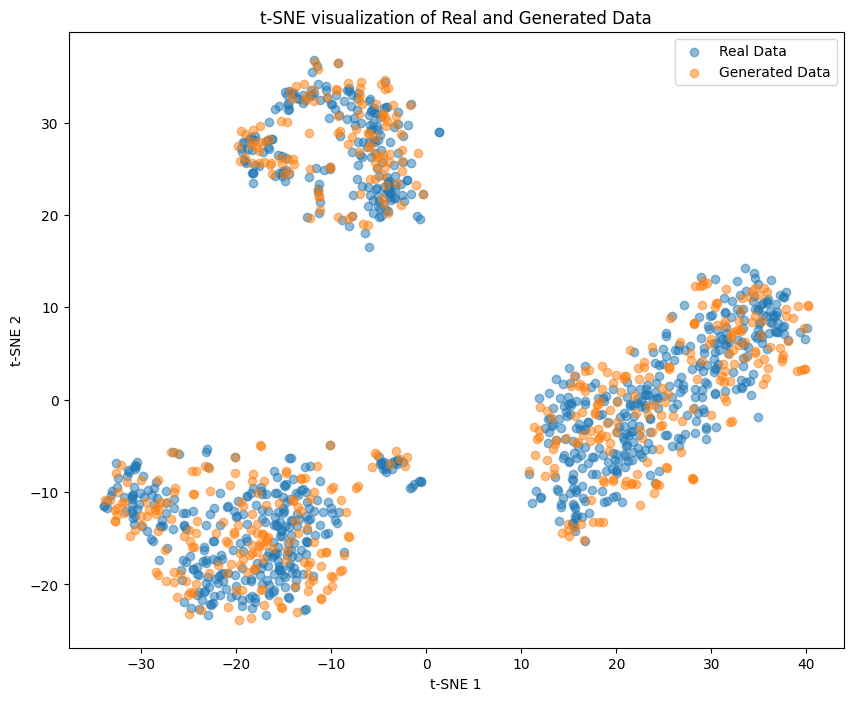

In [81]:
####Visualization
from sklearn.decomposition import PCA
# combine real data and generated data
combined_data = pd.concat([features, generated_df], axis=0)
labels = ['Real'] * len(features) + ['Generated'] * len(generated_df)
# PCA
pca = PCA(n_components=50) 
pca_result = pca.fit_transform(combined_data)
# t-SNE
tsne = TSNE(n_components=2, perplexity=40, n_iter=1000)
tsne_results = tsne.fit_transform(pca_result)

plt.figure(figsize=(10, 8))
plt.scatter(tsne_results[:len(features), 0], tsne_results[:len(features), 1], label='Real Data', alpha=0.5)
plt.scatter(tsne_results[len(features):, 0], tsne_results[len(features):, 1], label='Generated Data', alpha=0.5)
plt.legend()
plt.title('t-SNE visualization of Real and Generated Data')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
#plt.savefig('/central/groups/MZG/Wenqi/Dong/sccGAN/epoch_1000.pdf', format='pdf')

In [20]:
#save model
torch.save(gan.generator.state_dict(), CHECKPOINT_DIR / 'generator.pth')
torch.save(gan.critic.state_dict(), CHECKPOINT_DIR / 'critic.pth')

In [18]:
gan = cscGAN(latent_dim, input_dim, label_dim, gen_layers, critic_layers)
#load generatro
gan.generator.load_state_dict(torch.load(CHECKPOINT_DIR / 'generator.pth'))
#load critic
gan.critic.load_state_dict(torch.load(CHECKPOINT_DIR / 'critic.pth'))

<All keys matched successfully>

In [19]:
###generate specifc cell type data
def generate_celltype_data(generator, num_samples, latent_dim, celltype, device):
    with torch.no_grad(): 
        noise = torch.randn(num_samples, latent_dim, device=device)
        labels = torch.zeros((num_samples, 5), dtype=torch.float32, device=device)  # we have 5 cell types
        
        celltype_dict = {
            'PaE': 0,
            'Pre_EPI': 1, 
            'Pre_VE': 2,      
            'mTE': 3,
            'pTE': 4  # the order should be the same as your training labels
        }
        

        label_index = celltype_dict.get(celltype, None)
        if label_index is not None:
            labels[:, label_index] = 1.0 
        
        generated_data = generator(noise, labels).cpu().numpy()
        
    return generated_data

In [83]:

celltype = 'Pre_EPI'  # the cell type you want to generate
num_samples = 50  # number of cells
latent_dim = 100  
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') 

generated_data = generate_celltype_data(gan.generator, num_samples, latent_dim, celltype, device)
generated_df = pd.DataFrame(generated_data, columns=features.columns)

In [87]:
#save
generated_df.to_csv(OUTPUT_DIR / 'Generated_epi_data.csv', index=False)

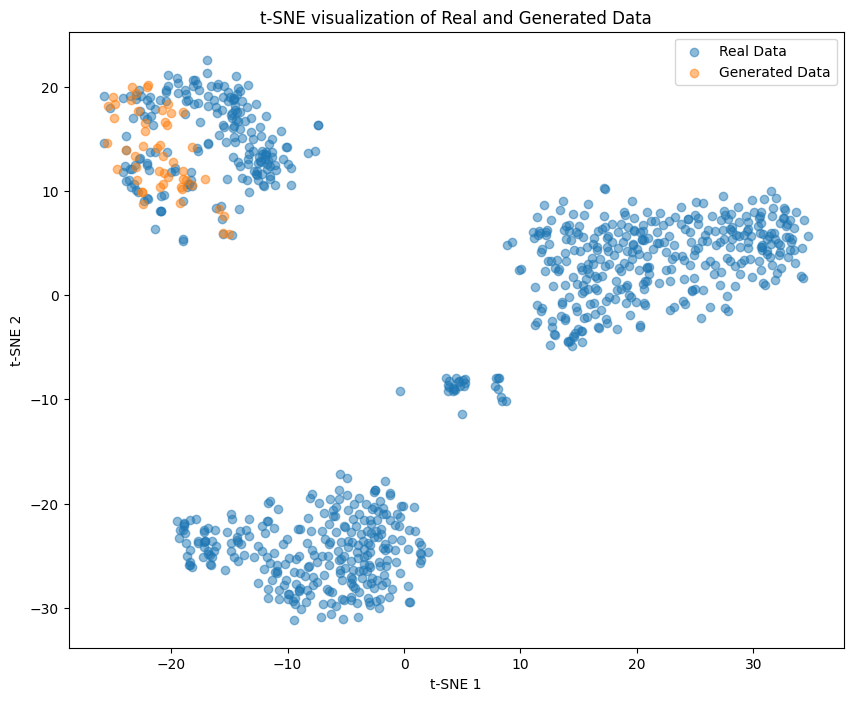

In [84]:
####Visualization
from sklearn.decomposition import PCA
combined_data = pd.concat([features, generated_df], axis=0)
labels = ['Real'] * len(features) + ['Generated'] * len(generated_df)

pca = PCA(n_components=50)  
pca_result = pca.fit_transform(combined_data)
tsne = TSNE(n_components=2, perplexity=40, n_iter=1000)
tsne_results = tsne.fit_transform(pca_result)

plt.figure(figsize=(10, 8))
plt.scatter(tsne_results[:len(features), 0], tsne_results[:len(features), 1], label='Real Data', alpha=0.5)
plt.scatter(tsne_results[len(features):, 0], tsne_results[len(features):, 1], label='Generated Data', alpha=0.5)
plt.legend()
plt.title('t-SNE visualization of Real and Generated Data')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()
#plt.savefig('/central/groups/MZG/Wenqi/Dong/sccGAN/Pre_EPI_generated.pdf', format='pdf')

In [86]:
#############Score of Blastoids #######################
# Since the GAN was trained in a label-conditioned manner (i.e., conditioned on cell type),
# scoring is more accurate when using real data from specific cell types as input.
# For example, to evaluate Rivron's blastoids, we use real TE and EPI cells separately
# to compute critic scores, which better reflects how well the GAN captures each lineage.
data = pd.read_csv('Rivron_EPI_expression.csv')

In [87]:
features = data.drop(['Unnamed: 0'], axis=1)
features = torch.tensor(features.values, dtype=torch.float32).to(device)

In [88]:
# Create 5 one-hot encoded labels
labels = torch.eye(5).to(device)  # Generate 5 labels, each as a one-hot vector

# Corresponding label names
label_names = ['PaE', 'Pre_EPI', 'Pre_VE', 'mTE', 'pTE']  # Label names corresponding to each index

# Compute critic scores for each label
scores = []
for i in range(5):
    label = labels[i].unsqueeze(0).expand(features.size(0), -1)  # Expand label to match batch size
    critic_score = gan.critic(features, label)  # Evaluate critic scores under this label
    avg_score = critic_score.mean().item()  # Calculate the average critic score
    scores.append(avg_score)

# Print the average score for each label
for i, score in enumerate(scores):
    print(f"Average critic score for label {label_names[i]}: {score:.4f}")
# Note:    
# If you are scoring using TE-like data (e.g., TE cells from blastoids),
# only the scores for 'mTE' and 'pTE' should be considered meaningful — ignore others.
# If you are scoring using EPI-like data, only the 'Pre_EPI' score is relevant.

标签 PaE 的平均评分: -1.6589
标签 Pre_EPI 的平均评分: -1.6772
标签 Pre_VE 的平均评分: -1.9631
标签 mTE 的平均评分: -0.3132
标签 pTE 的平均评分: -1.1070


In [ ]:
#解释性

In [18]:
device = torch.device("cpu")

gan.generator = gan.generator.to(device)
gan.critic = gan.critic.to(device)

real_data, real_labels = next(iter(dataloader))
real_data = real_data.to(device)
real_labels = real_labels.to(device)

real_data.requires_grad_(True)

gan.critic.zero_grad()
out = gan.critic(real_data, real_labels)
out.sum().backward()

importance = real_data.grad.abs().mean(dim=0).detach().cpu().numpy()

In [19]:
gene_names = features.columns.tolist()

import pandas as pd

df = pd.DataFrame({
    "gene": gene_names,
    "importance": importance
}).sort_values("importance", ascending=False)

print(df.head(100))

          gene  importance
686   Tor1aip1    0.063653
791     Golga3    0.057115
66       Gfod2    0.056990
292      Gkap1    0.055534
1961     Pde4d    0.055010
...        ...         ...
345    Arhgef3    0.042629
81       Lars2    0.042629
1859      Bri3    0.042536
1119     Mkrn1    0.042457
905      Folr1    0.042453

[100 rows x 2 columns]


In [24]:
top100 = df.head(100)
top100.to_csv("top100_genes.csv", index=False)

In [15]:
gene_names = features.columns.tolist()
label_names = celltype_labels.columns.tolist()

results = {}

for i, label_name in enumerate(label_names):
    print(f"Processing {label_name}...")

    # 选出该标签为1的样本
    idx = celltype_labels.iloc[:, i] == 1
    
    sub_feat = torch.tensor(features[idx].values, dtype=torch.float32)
    sub_lab = torch.tensor(celltype_labels[idx].values, dtype=torch.float32)

    sub_feat = sub_feat.to(device)
    sub_lab = sub_lab.to(device)

    sub_feat.requires_grad_(True)

    gan.critic.zero_grad()
    out = gan.critic(sub_feat, sub_lab)
    out.sum().backward()

    imp = sub_feat.grad.abs().mean(dim=0).detach().cpu().numpy()

    df = pd.DataFrame({
        "gene": gene_names,
        "importance": imp
    }).sort_values("importance", ascending=False)

    results[label_name] = df

    # 保存 top100
    df.head(100).to_csv(f"top100_{label_name}.csv", index=False)

Processing PaE...
Processing Pre_EPI...
Processing Pre_VE...
Processing mTE...
Processing pTE...


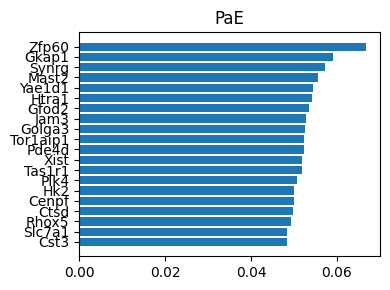

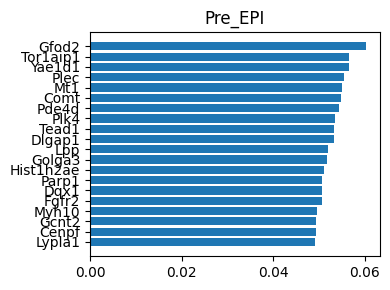

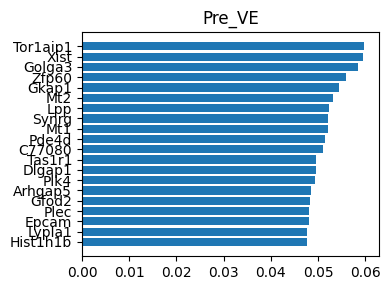

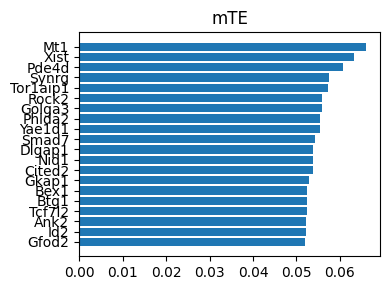

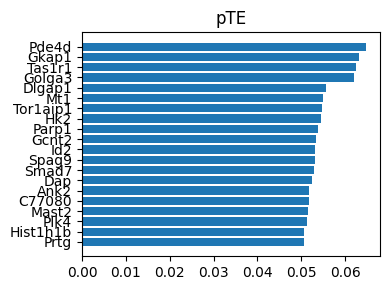

In [32]:
for k in results:
    df = results[k].head(20)
    
    plt.figure(figsize=(4,3))
    plt.barh(df["gene"][::-1], df["importance"][::-1])
    plt.title(k)
    plt.tight_layout()
    #plt.savefig(f"{k}_top10.pdf")
    #plt.close()

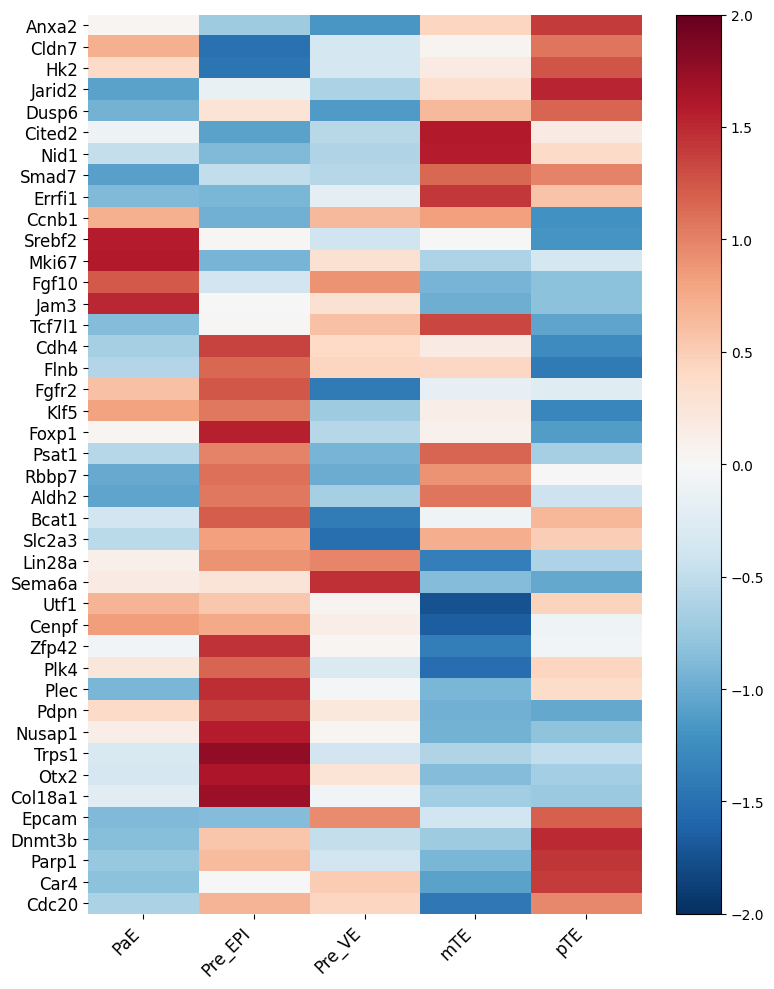

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, leaves_list
selected_genes = [
    "Otx2","Zfp42","Lin28a","Utf1","Klf5","Tcf7l1",
    "Foxp1","Trps1","Jarid2","Dnmt3b","Parp1","Rbbp7",
    "Fgfr2","Dusp6","Smad7","Errfi1","Fgf10","Cited2",
    "Epcam","Pdpn","Col18a1","Jam3","Cdh4","Cldn7",
    "Nid1","Car4","Sema6a","Anxa2","Plec","Flnb",
    "Psat1","Bcat1","Slc2a3","Hk2","Aldh2","Srebf2",
    "Cenpf","Mki67","Ccnb1","Nusap1","Plk4","Cdc20"
]
# 构建 plot_df
mat = []

for g in selected_genes:
    row = []
    for k in results:
        df_k = results[k].set_index("gene")
        val = df_k.loc[g]["importance"] if g in df_k.index else np.nan
        row.append(val)
    mat.append(row)

plot_df = pd.DataFrame(mat, index=selected_genes, columns=list(results.keys()))

data = plot_df.copy()

# z-score
data = data.sub(data.mean(axis=1), axis=0)
data = data.div(data.std(axis=1).replace(0, np.nan), axis=0)

mat = data.fillna(0).values

# 聚类
row_linkage = linkage(mat, method='average', metric='euclidean')
row_order = leaves_list(row_linkage)

mat = mat[row_order, :]
genes = data.index[row_order]

# ==== 画图 ====
fig, ax = plt.subplots(figsize=(8, 10))  # 图稍微拉高

im = ax.imshow(mat, aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2)

# 🔥 字体调大
ax.set_xticks(range(len(data.columns)))
ax.set_xticklabels(data.columns, rotation=45, ha='right', fontsize=12)

ax.set_yticks(range(len(genes)))
ax.set_yticklabels(genes, fontsize=12)   # ← 这里调大gene字体

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=10)

# 去边框
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig("heatmap.pdf")
plt.show()

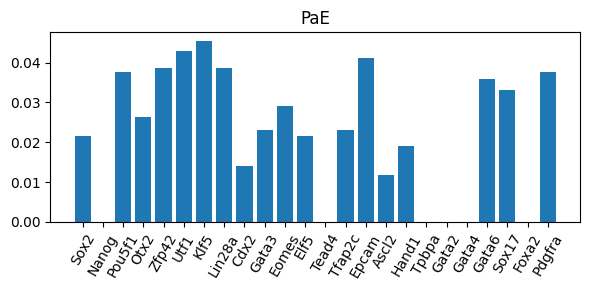

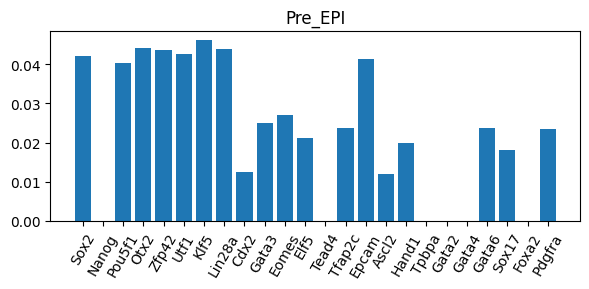

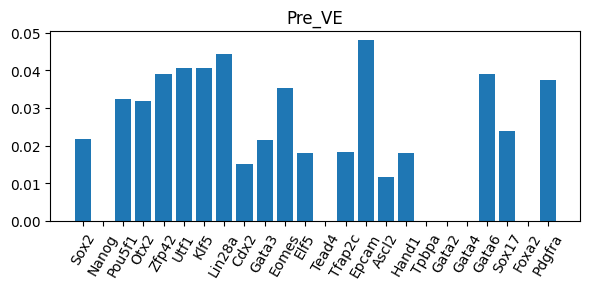

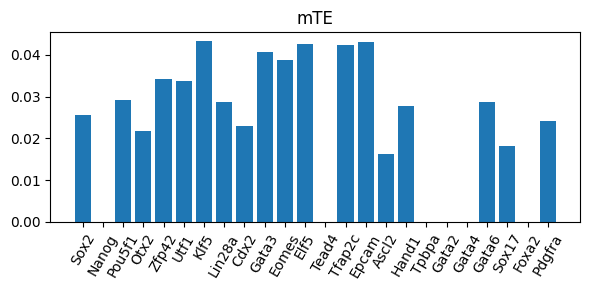

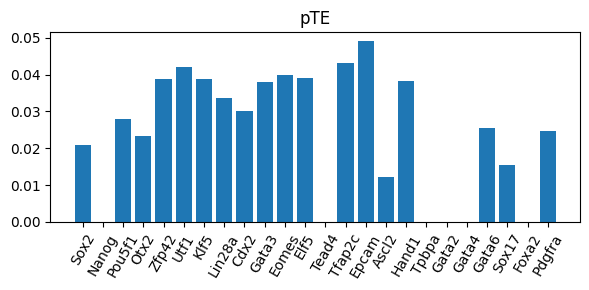

In [30]:
markers = [
    # EPI
    "Sox2","Nanog","Pou5f1","Otx2","Zfp42","Utf1","Klf5","Lin28a",

    # TE
    "Cdx2","Gata3","Eomes","Elf5","Tead4","Tfap2c","Epcam",

    # EPC / TGC
    "Ascl2","Hand1","Tpbpa","Gata2",

    # VE
    "Gata4","Gata6","Sox17","Foxa2","Pdgfra"
]
for k in results:
    df = results[k].set_index("gene")
    
    vals = []
    for m in markers:
        if m in df.index:
            vals.append(df.loc[m]["importance"])
        else:
            vals.append(0)
    
    plt.figure(figsize=(6,3))
    plt.bar(markers, vals)
    plt.title(f"{k}")
    plt.xticks(rotation=60)
    plt.tight_layout()
    #plt.savefig(f"{k}_markers.pdf")
    #plt.close()
    plt.show()